# Adverse Event Dot Plot (incidence and relative risk)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Two aligned panels summarise a trial's safety profile. The left panel shows how often each adverse event occurred in each arm; the right shows the relative risk with its 95% confidence interval on a log scale. Rows are sorted by relative risk, so events that are more common on treatment rise to the top without hiding how common they are.

## When to use

- Summarise many adverse event types from a two-arm trial on one page
- Spot safety signals, meaning events clearly more frequent on treatment, while keeping their absolute incidence in view
- Replace long adverse-event tables in a safety review or a data monitoring committee report

## Avoid when

- Events are very rare, so the intervals span orders of magnitude and dominate the panel (report counts)
- More than two arms need comparing (use one panel per comparison)
- Timing matters more than frequency (use cumulative incidence curves)

## Alternatives

- Forest plot
- Volcano plot of adverse events (risk difference vs. p-value)
- Cumulative incidence curves for key events

## Design tips

- Put relative risk on a log scale so 0.5 and 2 are equally far from 1
- Keep incidence next to relative risk; a doubled risk of a 0.5% event matters less than of a 20% event
- Sort by relative risk (or by incidence) rather than alphabetically

## Example

Simulated two-arm trial (250 patients per arm) reporting 20 adverse event types, with incidence on treatment and on placebo.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(90)
n_trt = n_ctl = 250
events = {  # adverse event: (placebo incidence, true relative risk)
    "Nausea": (0.12, 2.4), "Neutropenia": (0.06, 3.0), "Rash": (0.08, 2.2), "Fatigue": (0.20, 1.35),
    "Diarrhoea": (0.10, 1.6), "Alopecia": (0.03, 2.5), "Decreased appetite": (0.07, 1.5),
    "Peripheral neuropathy": (0.04, 1.8), "Anaemia": (0.09, 1.3), "Vomiting": (0.06, 1.4),
    "Headache": (0.14, 1.05), "Constipation": (0.09, 1.1), "Insomnia": (0.07, 0.95),
    "Back pain": (0.08, 0.9), "Cough": (0.10, 1.0), "Dizziness": (0.06, 1.1),
    "Upper resp. infection": (0.11, 0.85), "Arthralgia": (0.07, 0.8), "Hypertension": (0.05, 0.75),
    "Pyrexia": (0.05, 1.2),
}
rows = []
for name, (p0, rr) in events.items():
    x_ctl = rng.binomial(n_ctl, p0)
    x_trt = rng.binomial(n_trt, min(p0 * rr, 0.95))
    a, b = x_trt + 0.5, x_ctl + 0.5                      # 0.5 added to every cell of the 2x2 table
    log_rr = np.log((a / (n_trt + 1)) / (b / (n_ctl + 1)))
    se = np.sqrt(1 / a - 1 / (n_trt + 1) + 1 / b - 1 / (n_ctl + 1))
    rows.append((name, x_trt / n_trt, x_ctl / n_ctl, np.exp(log_rr),
                 np.exp(log_rr - 1.96 * se), np.exp(log_rr + 1.96 * se)))
ae = (pd.DataFrame(rows, columns=["event", "inc_trt", "inc_ctl", "rr", "rr_lo", "rr_hi"])
      .sort_values("rr").reset_index(drop=True))
ae.tail()

,event,inc_trt,inc_ctl,rr,rr_lo,rr_hi
15,Diarrhoea,0.176,0.076,2.282051,1.380381,3.772697
16,Nausea,0.296,0.112,2.614035,1.761642,3.878870
17,Alopecia,0.096,0.032,2.882353,1.347499,6.165467
18,Peripheral neuropathy,0.080,0.020,3.727273,1.478274,9.397823
19,Neutropenia,0.216,0.044,4.739130,2.571156,8.735120


### Plot

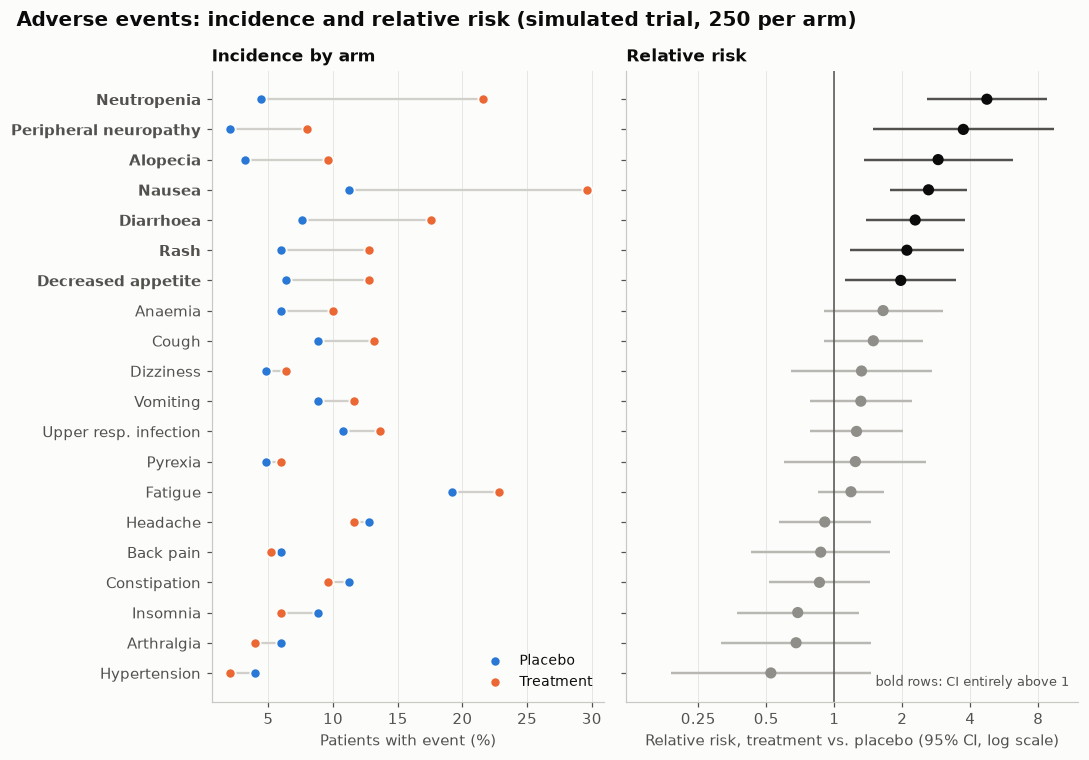

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 7), sharey=True, width_ratios=[1, 1.15])
y = np.arange(len(ae))
signal = ae["rr_lo"] > 1
ax1.hlines(y, ae[["inc_trt", "inc_ctl"]].min(axis=1) * 100, ae[["inc_trt", "inc_ctl"]].max(axis=1) * 100,
           color="#d0cfca", linewidth=1.5)
ax1.scatter(ae["inc_ctl"] * 100, y, s=45, color=PALETTE[0], label="Placebo", zorder=3,
            edgecolor="#fcfcfb", linewidth=1.2)
ax1.scatter(ae["inc_trt"] * 100, y, s=45, color=PALETTE[1], label="Treatment", zorder=3,
            edgecolor="#fcfcfb", linewidth=1.2)
ax1.set_yticks(y, ae["event"])
for lab, s in zip(ax1.get_yticklabels(), signal):
    lab.set_fontweight("bold" if s else "normal")
ax1.set_xlabel("Patients with event (%)")
ax1.set_title("Incidence by arm", fontsize=11)
ax1.legend(loc="lower right", fontsize=9)
ax1.grid(axis="y", visible=False)

ax2.hlines(y, ae["rr_lo"], ae["rr_hi"], color=np.where(signal, "#52514e", "#b8b7b1"), linewidth=1.6)
ax2.scatter(ae["rr"], y, s=40, color=np.where(signal, "#0b0b0b", "#8f8e88"), zorder=3)
ax2.axvline(1, color="#52514e", linewidth=1)
ax2.set_xscale("log")
ticks = [0.25, 0.5, 1, 2, 4, 8]
ax2.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax2.minorticks_off()
ax2.set_xlim(0.12, 12)
ax2.set_xlabel("Relative risk, treatment vs. placebo (95% CI, log scale)")
ax2.set_title("Relative risk", fontsize=11)
ax2.grid(axis="y", visible=False)
ax2.text(0.98, 0.02, "bold rows: CI entirely above 1", transform=ax2.transAxes, ha="right",
         va="bottom", fontsize=8.5, color="#52514e")
fig.suptitle("Adverse events: incidence and relative risk (simulated trial, 250 per arm)",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Read each row across. The left dots show incidence in each arm, and the right dot the relative risk with its 95% interval. Rows near the top, with intervals entirely right of 1, are the safety signals (bold labels). Neutropenia, nausea and diarrhoea are both common and clearly elevated; rash and decreased appetite are elevated with intervals just clear of 1; alopecia and peripheral neuropathy are elevated too, but rarer.

## Reference

This method comes from the research literature:

- Amit, O., Heiberger, R. M. & Lane, P. W. (2008). Graphical approaches to the analysis of safety data from clinical trials. Pharmaceutical Statistics 7(1), 20–35. <https://doi.org/10.1002/pst.254>

---
Standalone script: [`adverse_event_dotplot.py`](adverse_event_dotplot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)